In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
# 1. Load the dataset
df = pd.read_csv('data/atp_tennis.csv')
print(f"Total rows loaded: {len(df)}")
print(df.head(3))

Total rows loaded: 69100
                           Tournament        Date         Series    Court  \
0  Australian Hardcourt Championships  2000-01-03  International  Outdoor   
1  Australian Hardcourt Championships  2000-01-03  International  Outdoor   
2  Australian Hardcourt Championships  2000-01-03  International  Outdoor   

  Surface      Round  Best of     Player_1      Player_2        Winner  \
0    Hard  1st Round        3   Arthurs W.  Gambill J.M.  Gambill J.M.   
1    Hard  1st Round        3  Balcells J.     Henman T.     Henman T.   
2    Hard  1st Round        3   Clement A.    Enqvist T.    Enqvist T.   

   Rank_1  Rank_2  Pts_1  Pts_2  Odd_1  Odd_2        Score  
0     105      58     -1     -1   -1.0   -1.0  6-3 6-7 4-6  
1     218      11     -1     -1   -1.0   -1.0      4-6 6-7  
2      56       5     -1     -1   -1.0   -1.0      3-6 3-6  


In [3]:
# 2. Clean & Parse Dates
df['Date'] = pd.to_datetime(df['Date'])
# Drop rows where player rankings are missing or invalid (-1 is sometimes used for unranked)
df = df[(df['Rank_1'] > 0) & (df['Rank_2'] > 0)].dropna(subset=['Rank_1', 'Rank_2', 'Winner', 'Surface'])

In [4]:
# 3. Create Target Variable (1 if Player_1 won, 0 if Player_2 won)
df['Player_1_Win'] = (df['Winner'] == df['Player_1']).astype(int)

In [5]:
# 4. Feature Engineering (Strictly pre-match info to avoid leakage!)
# Positive Rank_Diff means Player 1 is higher-ranked (smaller rank number = better)
df['Rank_Diff'] = df['Rank_2'] - df['Rank_1']


In [6]:
# 5. Establish the "Dumb" Baseline: Higher-ranked player always wins
baseline_preds = (df['Rank_1'] < df['Rank_2']).astype(int)
baseline_acc = (baseline_preds == df['Player_1_Win']).mean()

print(f"\nCleaned dataset size: {len(df)} matches")
print(f"Baseline Accuracy (Higher-ranked player always wins): {baseline_acc:.3f}")


Cleaned dataset size: 69074 matches
Baseline Accuracy (Higher-ranked player always wins): 0.653


In [7]:
# Check baseline accuracy by court surface
df['Higher_Rank_Won'] = (baseline_preds == df['Player_1_Win'])
surface_stats = df.groupby('Surface')['Higher_Rank_Won'].agg(['count', 'mean']).reset_index()
print("\nHigher-Ranked Win Rate by Surface:")
print(surface_stats)


Higher-Ranked Win Rate by Surface:
  Surface  count      mean
0  Carpet   1632  0.622549
1    Clay  22144  0.645322
2   Grass   7729  0.654289
3    Hard  37569  0.658655


C:\Users\desti\AppData\Local\Temp\ipykernel_7004\1110984043.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=surface_stats, x='Surface', y='mean', palette='viridis')


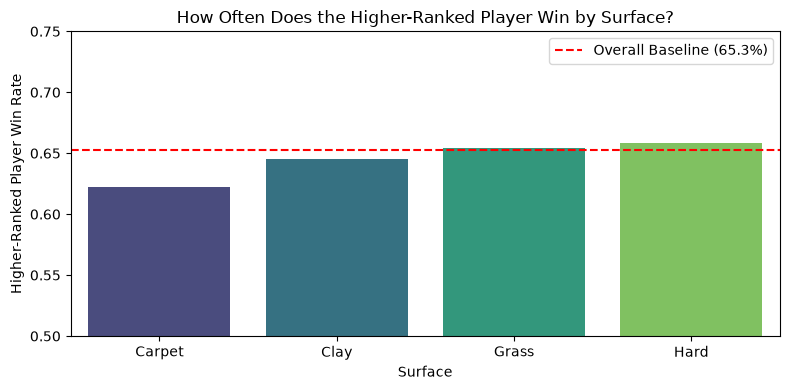

In [8]:
# Plot win rate across surfaces
plt.figure(figsize=(8, 4))
sns.barplot(data=surface_stats, x='Surface', y='mean', palette='viridis')
plt.axhline(baseline_acc, color='red', linestyle='--', label=f'Overall Baseline ({baseline_acc:.1%})')
plt.title('How Often Does the Higher-Ranked Player Win by Surface?')
plt.ylabel('Higher-Ranked Player Win Rate')
plt.ylim(0.5, 0.75)
plt.legend()
plt.tight_layout()
plt.show()

In [9]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# 1. Select strictly pre-match features and target
X = df[['Rank_Diff', 'Surface', 'Court', 'Best of']]
y = df['Player_1_Win']

# 2. Split FIRST (80/20 train/test split with random_state for reproducibility)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# 3. Preprocess inside a Pipeline (scale numeric columns, one-hot encode categories)
preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), ['Rank_Diff', 'Best of']),
        ('cat', OneHotEncoder(drop='first'), ['Surface', 'Court'])
    ]
)

model = Pipeline([
    ('prep', preprocessor),
    ('clf', LogisticRegression())
])

# 4. Fit on training rows ONLY, then evaluate once on the test set
model.fit(X_train, y_train)
y_pred = model.predict(X_test)

print(f"Logistic Regression Test Accuracy: {accuracy_score(y_test, y_pred):.3f}")
print("\nConfusion Matrix:\n", confusion_matrix(y_test, y_pred))
print("\nClassification Report:\n", classification_report(y_test, y_pred))

Logistic Regression Test Accuracy: 0.651

Confusion Matrix:
 [[4511 2396]
 [2421 4487]]

Classification Report:
               precision    recall  f1-score   support

           0       0.65      0.65      0.65      6907
           1       0.65      0.65      0.65      6908

    accuracy                           0.65     13815
   macro avg       0.65      0.65      0.65     13815
weighted avg       0.65      0.65      0.65     13815

